In [1]:
import sys

print(sys.executable)

C:\Users\jugal\langchain-env\Scripts\python.exe


# Let's first create a simple workflow to understand the syntax of LangGraph. Here, we will not use anny LLM.
# We will create a workflow to calculate `BMI` where input will be `height` and `weight`.

# Input--->Calc_bmi---> output

Now think for a while, what will be the states we will have to maintain?

Correct, we will have 3 key value pairs. They're `Height`, `Weight` and `Result`.

In [2]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import Annotated, Optional

In [3]:
# Define State: This will be the pydantic's or TypedDict's  objcet

class BMIState(BaseModel):

    height_m: Annotated[float, Field(description = 'Height of a person')]
    weight_kg: Annotated[float, Field(description = "Weight of a person")]
    
    bmi: Annotated[Optional[float], Field(description = "BMI of a person", default = None)]

In [4]:
# Creating a function: In langGraph nodes are nothing but functions.

def calc_bmi(State: BMIState) -> BMIState:

    weight_kg = State.weight_kg
    height_m = State.height_m

    bmi = weight_kg/ (height_m**2)    # Weight multiply with height's square

    # return bmi
    return {"bmi": round(bmi, 2)}

In [6]:
# Defining graph
graph = StateGraph(BMIState)

# Adding nodes to the graph
graph.add_node('calculate_bmi', calc_bmi)    # add_node(name_of_the_node, function)

# Add edges to the graph.
graph.add_edge(START, 'calculate_bmi')    # Means first edge is starting from Start and going towards calculate_bmi (Node)
                                        # Start ---> calculate_bmi

graph.add_edge('calculate_bmi', END)    # Second edge is from calculate_bmi to END
                                        # calculate_bmi ---> End

# Final graph: START ---> calculate_bmi ---> END

# Compiling the graph
workflow = graph.compile()

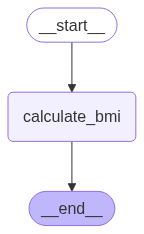

In [7]:
workflow

In [8]:
initial_state = {'weight_kg': 50, 'height_m': 1.73}

final_state = workflow.invoke(initial_state)

In [9]:
final_state

{'height_m': 1.73, 'weight_kg': 50, 'bmi': 16.71}

In [ ]:
# This is the special functionality of langGraph, that even if we return partial state, LangGraph
# will merge the whole state.

# In simple python code, the above function would only return "bmi" unlike whole state here.

# Using TypedDict: `Mostly TypedDict is used in LangGraph`

In [14]:
from typing import TypedDict

In [15]:
class BMIState(TypedDict):

    weight_kg: float
    height_m: float
    bmi: float

In [16]:
# Creating a function: In langGraph nodes are nothing but functions.

def calc_bmi(State: BMIState) -> BMIState:

    weight_kg = State['weight_kg']
    height_m = State['height_m']

    bmi = weight_kg/ (height_m**2)    # Weight multiply with height's square

    # return bmi
    return {"bmi": round(bmi, 2)}

In [17]:
# Defining graph
graph = StateGraph(BMIState)

# Adding nodes
graph.add_node('calculate_bmi', calc_bmi)

# Creating edges
graph.add_edge(START, 'calculate_bmi')
graph.add_edge('calculate_bmi', END)

# Cpmpiling the graph

workflow = graph.compile()

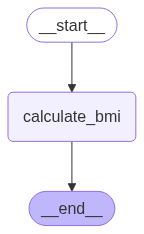

In [18]:
workflow

In [19]:
initial_state = {"height_m": 1.75, "weight_kg": 50}

final_state = workflow.invoke(initial_state)

In [20]:
final_state

{'weight_kg': 50, 'height_m': 1.75, 'bmi': 16.33}

# Now, lets add one more node to get the category of the person as `fit`, `overweight`, `obese`.

In [22]:
class BMIState(TypedDict):

    weight_kg: float
    height_m: float
    bmi: float
    category: str

In [23]:
# Creating nodes (Function)

def calc_bmi(State: BMIState) -> BMIState:

    weight = State['weight_kg']
    height = State['height_m']

    bmi = weight/ (height**2)
    
    # return bmi
    return {"bmi": round(bmi, 2)}
    
# ----------------------------------------------------

def category(State: BMIState) -> BMIState:

    bmi = State['bmi']

    if bmi < 18.5:
        return {'category': 'Underweight'}
    elif 18.5 < bmi < 25:
        return {'category': 'Normal'}
    elif 25 < bmi < 30:
        return {'category': 'Overweight'}
    else:
        return {'category': 'Obese'}

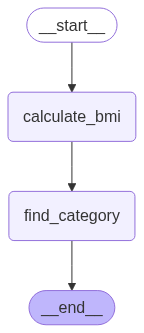

In [24]:
# Defining graph
graph = StateGraph(BMIState)

# Adding nodes
graph.add_node('calculate_bmi', calc_bmi)
graph.add_node('find_category', category)

# Creating edges

graph.add_edge(START, 'calculate_bmi')
graph.add_edge('calculate_bmi', 'find_category')
graph.add_edge('find_category', END)

workflow = graph.compile()

workflow

In [25]:
initial_state = {'weight_kg': 50, 'height_m': 1.75}
final_state = workflow.invoke(initial_state)

print(final_state)

{'weight_kg': 50, 'height_m': 1.75, 'bmi': 16.33, 'category': 'Underweight'}


# In next notebook, we will learn to create LLM based workflow